In [1]:
!pip install nltk scikit-learn tensorflow matplotlib wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB ?  0:01:10/s eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 10.4 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 9.8 MB/s  0:00:00m399.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 2.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 11.3 MB/s  0:00:02eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 10.9 MB/s  0:00:01eta 0:00:01
   ━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━  7/18 [numpy]  WARNING: The scripts f2py and numpy-config are installed in '/home/7e61c14b-463b-46bc-9e46-b02866aa5c25/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this w

In [4]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/

True

Original Text:
 
Artificial Intelligence is transforming the world of technology.
AI helps computers learn from data and solve complex problems.
Machine learning and deep learning are important parts of Artificial Intelligence.
AI is used in healthcare, education, business, and transportation.
In the future, Artificial Intelligence will continue to improve our lives.


Cleaned Text:
 
artificial intelligence is transforming the world of technology
ai helps computers learn from data and solve complex problems
machine learning and deep learning are important parts of artificial intelligence
ai is used in healthcare education business and transportation
in the future artificial intelligence will continue to improve our lives


Word Tokens:
 ['Artificial', 'Intelligence', 'is', 'transforming', 'the', 'world', 'of', 'technology', '.', 'AI', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', '.', 'Machine', 'learning', 'and', 'deep', 'learning', 'are', 'imp

Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': 'Top 10 Word Frequencies'}, xlabel='Samples', ylabel='Counts'>

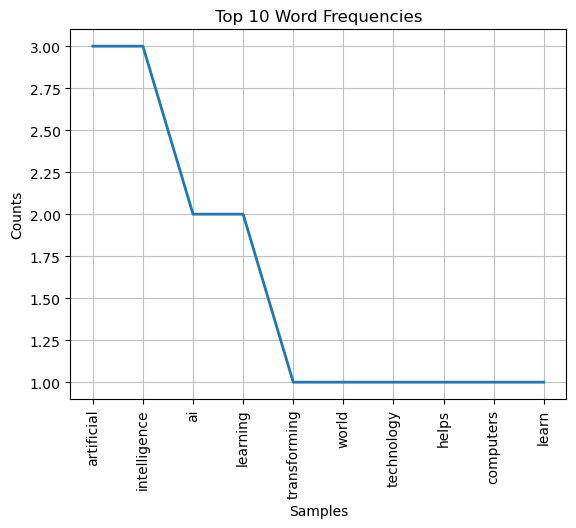

In [5]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Paragraph about Artificial Intelligence
text = """
Artificial Intelligence is transforming the world of technology.
AI helps computers learn from data and solve complex problems.
Machine learning and deep learning are important parts of Artificial Intelligence.
AI is used in healthcare, education, business, and transportation.
In the future, Artificial Intelligence will continue to improve our lives.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("Original Text:\n", text)
print("\nCleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():")
print(text.split())

print("\nUsing word_tokenize():")
print(word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in word_tokenize(clean_text)
    if word.isalpha() and word not in stop_words
]

print("\nWords After Stopword Removal:\n", filtered_words)

# 5. Display word frequency distribution
frequency = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(word, ":", count)

# Plot frequency distribution
frequency.plot(10, title="Top 10 Word Frequencies")

In [6]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Use the same paragraph as Q1
text = """
Artificial Intelligence is transforming the world of technology.
AI helps computers learn from data and solve complex problems.
Machine learning and deep learning are important parts of Artificial Intelligence.
AI is used in healthcare, education, business, and transportation.
In the future, Artificial Intelligence will continue to improve our lives.
"""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Alphabetic Words:\n", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Perform stemming
stemmer = PorterStemmer()

stemmed_words = [
    stemmer.stem(word)
    for word in filtered_words
]

print("\nStemmed Words:\n", stemmed_words)

# 4. Perform lemmatization
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print("\nLemmatized Words:\n", lemmatized_words)

# 5. Compare results
print("\nComparison of Stemming and Lemmatization:")

for original, stemmed, lemmatized in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(
        f"Original: {original:15} "
        f"Stemmed: {stemmed:12} "
        f"Lemmatized: {lemmatized}"
    )

Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'of', 'technology', 'ai', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'machine', 'learning', 'and', 'deep', 'learning', 'are', 'important', 'parts', 'of', 'artificial', 'intelligence', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'business', 'and', 'transportation', 'in', 'the', 'future', 'artificial', 'intelligence', 'will', 'continue', 'to', 'improve', 'our', 'lives']

After Stopword Removal:
 ['artificial', 'intelligence', 'transforming', 'world', 'technology', 'ai', 'helps', 'computers', 'learn', 'data', 'solve', 'complex', 'problems', 'machine', 'learning', 'deep', 'learning', 'important', 'parts', 'artificial', 'intelligence', 'ai', 'used', 'healthcare', 'education', 'business', 'transportation', 'future', 'artificial', 'intelligence', 'continue', 'improve', 'lives']

Stemmed Words:
 ['artifici', 'intellig', 'transform', 'world', 'technolog', '

In [7]:
re.findall(r'\b[a-zA-Z]+\b', text.lower())

['artificial',
 'intelligence',
 'is',
 'transforming',
 'the',
 'world',
 'of',
 'technology',
 'ai',
 'helps',
 'computers',
 'learn',
 'from',
 'data',
 'and',
 'solve',
 'complex',
 'problems',
 'machine',
 'learning',
 'and',
 'deep',
 'learning',
 'are',
 'important',
 'parts',
 'of',
 'artificial',
 'intelligence',
 'ai',
 'is',
 'used',
 'in',
 'healthcare',
 'education',
 'business',
 'and',
 'transportation',
 'in',
 'the',
 'future',
 'artificial',
 'intelligence',
 'will',
 'continue',
 'to',
 'improve',
 'our',
 'lives']

In [8]:
print(lemmatizer.lemmatize("running", pos="v"))
print(lemmatizer.lemmatize("studies", pos="v"))
print(lemmatizer.lemmatize("better", pos="a"))

run
study
good


In [9]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts
texts = [
    "Artificial intelligence helps computers learn from data",
    "Machine learning improves artificial intelligence systems",
    "Data science uses machine learning for predictions"
]

# 1. Bag of Words using CountVectorizer
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(texts)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF representation
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

# 3. Find top three keywords for each text
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords for Each Text:")

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()

    top_indices = scores.argsort()[::-1][:3]

    keywords = [
        (feature_names[index], scores[index])
        for index in top_indices
        if scores[index] > 0
    ]

    print(f"\nText {i + 1}: {text}")

    for word, score in keywords:
        print(f"{word}: {score:.4f}")

Vocabulary:
['artificial' 'computers' 'data' 'for' 'from' 'helps' 'improves'
 'intelligence' 'learn' 'learning' 'machine' 'predictions' 'science'
 'systems' 'uses']

Bag of Words Matrix:
[[1 1 1 0 1 1 0 1 1 0 0 0 0 0 0]
 [1 0 0 0 0 0 1 1 0 1 1 0 0 1 0]
 [0 0 1 1 0 0 0 0 0 1 1 1 1 0 1]]

TF-IDF Matrix:
[[0.31757018 0.41756662 0.31757018 0.         0.41756662 0.41756662
  0.         0.31757018 0.41756662 0.         0.         0.
  0.         0.         0.        ]
 [0.36617957 0.         0.         0.         0.         0.
  0.48148213 0.36617957 0.         0.36617957 0.36617957 0.
  0.         0.48148213 0.        ]
 [0.         0.         0.31757018 0.41756662 0.         0.
  0.         0.         0.         0.31757018 0.31757018 0.41756662
  0.41756662 0.         0.41756662]]

Top 3 Keywords for Each Text:

Text 1: Artificial intelligence helps computers learn from data
learn: 0.4176
helps: 0.4176
from: 0.4176

Text 2: Machine learning improves artificial intelligence systems
systems:

In [10]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two short texts
text1 = """
Artificial Intelligence enables computers to perform intelligent tasks.
It helps machines learn from data.
AI is widely used in healthcare and education.
It can automate repetitive tasks.
AI systems can improve decision making.
Artificial Intelligence is becoming increasingly important.
"""

text2 = """
Blockchain technology stores information in distributed ledgers.
It provides transparency and security for transactions.
Blockchain can be used in finance and supply chains.
It reduces dependence on centralized systems.
Blockchain technology supports decentralized applications.
It is becoming increasingly important in digital transactions.
"""

# 1. Preprocess and tokenize both texts
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens of Text 1:")
print(tokens1)

print("\nTokens of Text 2:")
print(tokens2)

# 2(a). Calculate Jaccard similarity
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:")
print(intersection)

print("\nJaccard Similarity:", round(jaccard, 4))

# 2(b). Calculate Cosine similarity using TF-IDF
documents = [text1, text2]

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 4))

# 3. Compare the results
print("\nSimilarity Analysis:")

if jaccard > cosine:
    print("Jaccard similarity is higher for these texts.")
elif cosine > jaccard:
    print("Cosine similarity is higher for these texts.")
else:
    print("Both similarity scores are equal.")

print(
    "Jaccard measures the overlap between unique words, "
    "whereas cosine similarity compares TF-IDF-weighted vectors."
)

Tokens of Text 1:
['artificial', 'intelligence', 'enables', 'computers', 'to', 'perform', 'intelligent', 'tasks', 'it', 'helps', 'machines', 'learn', 'from', 'data', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'and', 'education', 'it', 'can', 'automate', 'repetitive', 'tasks', 'ai', 'systems', 'can', 'improve', 'decision', 'making', 'artificial', 'intelligence', 'is', 'becoming', 'increasingly', 'important']

Tokens of Text 2:
['blockchain', 'technology', 'stores', 'information', 'in', 'distributed', 'ledgers', 'it', 'provides', 'transparency', 'and', 'security', 'for', 'transactions', 'blockchain', 'can', 'be', 'used', 'in', 'finance', 'and', 'supply', 'chains', 'it', 'reduces', 'dependence', 'on', 'centralized', 'systems', 'blockchain', 'technology', 'supports', 'decentralized', 'applications', 'it', 'is', 'becoming', 'increasingly', 'important', 'in', 'digital', 'transactions']

Common Words:
{'in', 'can', 'systems', 'increasingly', 'and', 'is', 'used', 'becoming', 'it', 'impo

In [21]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [1]:
import wordcloud

print("WordCloud installed successfully!")

WordCloud installed successfully!


In [2]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "wordcloud"
])

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


0

In [3]:
import sys

print("Python executable:", sys.executable)

%pip show wordcloud

Python executable: /opt/conda/envs/anaconda-2025.12-py312/bin/python
Name: wordcloud
Version: 1.9.6
Summary: A little word cloud generator
Home-page: https://github.com/amueller/word_cloud
Author: 
Author-email: Andreas Mueller <t3kcit+wordcloud@gmail.com>
License-Expression: MIT
Location: /home/7e61c14b-463b-46bc-9e46-b02866aa5c25/.local/lib/python3.12/site-packages
Requires: matplotlib, numpy, pillow
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/7e61c14b-463b-46bc-9e46-
[nltk_data]     b02866aa5c25/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Sentiment Analysis Results:

Review: This phone has an amazing camera and excellent battery life.
Scores: {'neg': 0.0, 'neu': 0.516, 'pos': 0.484, 'compound': 0.8176}
Sentiment: Positive
------------------------------------------------------------
Review: The laptop is fast, reliable, and worth the money.
Scores: {'neg': 0.0, 'neu': 0.808, 'pos': 0.192, 'compound': 0.2263}
Sentiment: Positive
------------------------------------------------------------
Review: The headphones have fantastic sound quality.
Scores: {'neg': 0.0, 'neu': 0.581, 'pos': 0.419, 'compound': 0.5574}
Sentiment: Positive
------------------------------------------------------------
Review: The product is terrible and stopped working after two days.
Scores: {'neg': 0.385, 'neu': 0.615, 'pos': 0.0, 'compound': -0.6124}
Sentiment: Negative
------------------------------------------------------------
Review: The battery drains quickly and the performance is disappointing.
Scores: {'neg': 0.286, 'neu': 0.714, 'pos': 0.0,

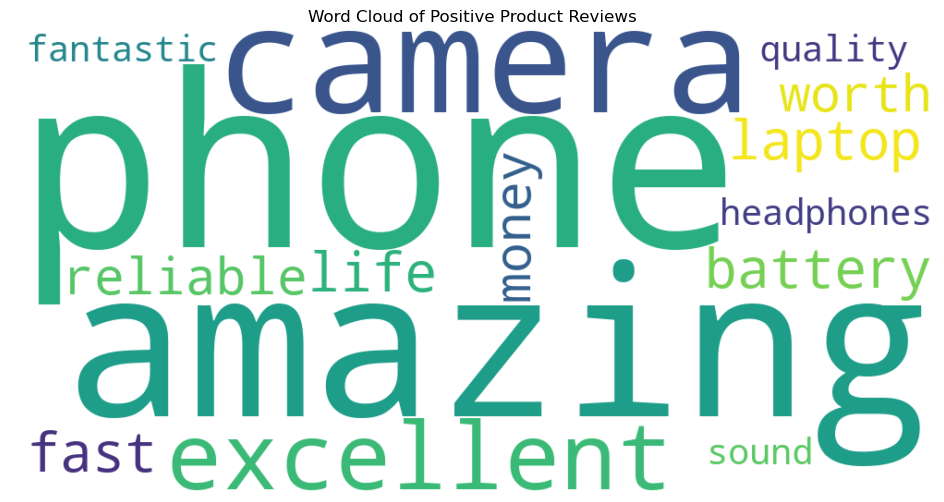

In [6]:
import nltk
import matplotlib.pyplot as plt

from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

# Download VADER lexicon if required
nltk.download('vader_lexicon')

# Sample product reviews
reviews = [
    "This phone has an amazing camera and excellent battery life.",
    "The laptop is fast, reliable, and worth the money.",
    "The headphones have fantastic sound quality.",
    "The product is terrible and stopped working after two days.",
    "The battery drains quickly and the performance is disappointing.",
    "The device is expensive and the customer service is poor.",
    "The phone arrived yesterday.",
    "The package contains a charger and a USB cable.",
    "The laptop has a 15-inch display."
]

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

positive_reviews = []

print("Sentiment Analysis Results:\n")

# 1 and 2. Calculate sentiment and classify reviews
for review in reviews:
    scores = sia.polarity_scores(review)
    compound = scores['compound']

    if compound >= 0.05:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif compound <= -0.05:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Scores:", scores)
    print("Sentiment:", sentiment)
    print("-" * 60)

# 3. Create word cloud for positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=set(nltk.corpus.stopwords.words('english'))
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Product Reviews")
    plt.show()
else:
    print("No positive reviews available for the word cloud.")

In [7]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Artificial intelligence is changing the modern world.
Machine learning helps computers learn patterns from data.
Deep learning uses neural networks to solve complex problems.
Natural language processing enables computers to understand human language.
Artificial intelligence is used in healthcare, education, finance, and transportation.
These technologies help automate tasks and improve productivity.
Data plays an important role in building intelligent systems.
Machine learning models require suitable training data.
Researchers continue to develop safer and more reliable artificial intelligence systems.
In the future, artificial intelligence may help solve many important challenges.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()

tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary Size:", total_words)

# Create input sequences
input_sequences = []

for line in text.lower().split('\n'):
    line = line.strip()

    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i + 1]
        input_sequences.append(n_gram_sequence)

# Pad sequences to equal length
max_sequence_len = max(len(sequence) for sequence in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# Split predictors and labels
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

# One-hot encode output labels
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

# 3. Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32,
        input_length=max_sequence_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# Train the model
model.fit(
    X,
    y,
    epochs=150,
    verbose=1
)

# Function to generate text
def generate_text(seed_text, next_words=25):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre'
        )

        predicted_probabilities = model.predict(
            token_list,
            verbose=0
        )[0]

        predicted_word_index = int(
            np.argmax(predicted_probabilities)
        )

        output_word = None

        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if output_word is None:
            break

        seed_text += " " + output_word

    return seed_text

# Generate 2-3 lines from a seed phrase
seed = "artificial intelligence"

generated_text = generate_text(seed, next_words=30)

print("\nGenerated Text:\n")
print(generated_text)

I0000 00:00:1793178963.321266     609 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793178964.072746     609 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793178967.658214     609 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Vocabulary Size: 65
Input Shape: (79, 10)
Output Shape: (79, 65)


/home/7e61c14b-463b-46bc-9e46-b02866aa5c25/.local/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1793178968.553497     609 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.0000e+00 - loss: 4.1749
Epoch 2/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0886 - loss: 4.1692
Epoch 3/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1139 - loss: 4.1648
Epoch 4/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1266 - loss: 4.1604
Epoch 5/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1266 - loss: 4.1548
Epoch 6/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1266 - loss: 4.1482
Epoch 7/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1139 - loss: 4.1405
Epoch 8/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1013 - loss: 4.1299
Epoch 9/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0759 - loss: 4.1135
Epoch 10/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0886 - loss: 4.0933
Epoch 11/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1013 - loss: 4.0618
Epoch 12/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1013 